In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/full_datasets/dwd_01975_air_temperature_hourly.csv",
                 parse_dates=["time"]
)

df.head()

,time,STATIONS_ID,MESS_DATUM,QN_9,TT_TU,RF_TU,source
0,2024-04-01 00:00:00,1975,2024040100,3,7.9,91.0,historical
1,2024-04-01 01:00:00,1975,2024040101,3,7.6,93.0,historical
2,2024-04-01 02:00:00,1975,2024040102,3,7.5,93.0,historical
3,2024-04-01 03:00:00,1975,2024040103,3,7.1,94.0,historical
4,2024-04-01 04:00:00,1975,2024040104,3,6.8,95.0,historical


In [12]:
#Grundlegende Übersicht der Daten

In [13]:
print(f"Anzahl Zeilen: {len(df):,}")
print(f"Anzahl Spalten: {len(df.columns)}")

Anzahl Zeilen: 23,040
Anzahl Spalten: 7


In [14]:
print("Erster Datensatz:", df["time"].min())
print("Letzter Datensatz:", df["time"].max())

Erster Datensatz: 2024-04-01 00:00:00
Letzter Datensatz: 2026-11-16 23:00:00


In [15]:
print("Anzahl Stationen:", df["STATIONS_ID"].nunique())
print(df["STATIONS_ID"].unique())

Anzahl Stationen: 1
[1975]


In [16]:
#Fehlende Werte

In [17]:
missing = df.isna().sum()

missing_df = pd.DataFrame({
    "missing_count": missing,
    "missing_percent": 100 * missing / len(df)
})

display(missing_df)

,missing_count,missing_percent
time,0,0.000000
STATIONS_ID,0,0.000000
MESS_DATUM,0,0.000000
QN_9,0,0.000000
TT_TU,153,0.664062
RF_TU,181,0.785590
source,0,0.000000


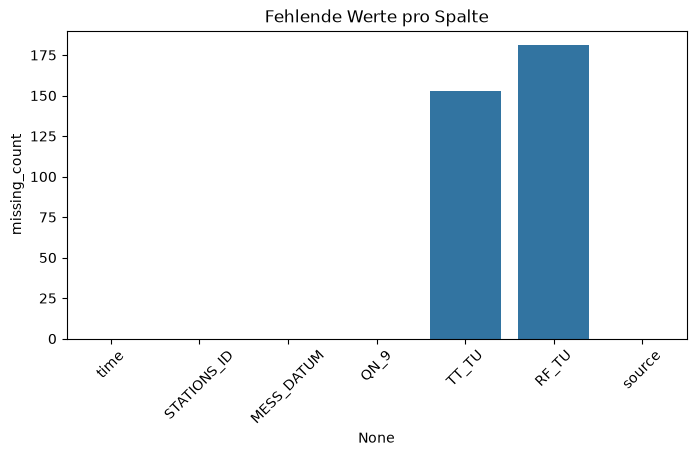

In [21]:
plt.figure(figsize=(8,4))
sns.barplot(
    x=missing_df.index,
    y=missing_df["missing_count"]
)
plt.xticks(rotation=45)
plt.title("Fehlende Werte pro Spalte")
plt.show()

In [ ]:
##alle Stunden und Tage vorhanden?

In [22]:
full_range = pd.date_range(
    start=df["time"].min(),
    end=df["time"].max(),
    freq="h"
)

missing_times = full_range.difference(df["time"])

print("Fehlende Stunden:", len(missing_times))

Fehlende Stunden: 0


In [23]:
df["date"] = df["time"].dt.date

daily_counts = df.groupby("date").size()

incomplete_days = daily_counts[daily_counts != 24]

print(f"Unvollständige Tage: {len(incomplete_days)}")
display(incomplete_days.head(20))

Unvollständige Tage: 0


Series([], dtype: int64)

In [ ]:
#Temperaturverteilung

In [3]:
outliers = df[
    (df["TT_TU"] < -50) |
    (df["TT_TU"] > 50)
]

print(
    f"Verdächtige Datensätze: {len(outliers)}"
)

outliers.head()

Verdächtige Datensätze: 0


,time,STATIONS_ID,MESS_DATUM,QN_9,TT_TU,RF_TU,source


In [24]:
df["TT_TU"].describe()

count    22887.000000
mean        11.383786
std          7.323001
min        -13.400000
25%          6.000000
50%         11.800000
75%         16.700000
max         38.800000
Name: TT_TU, dtype: float64

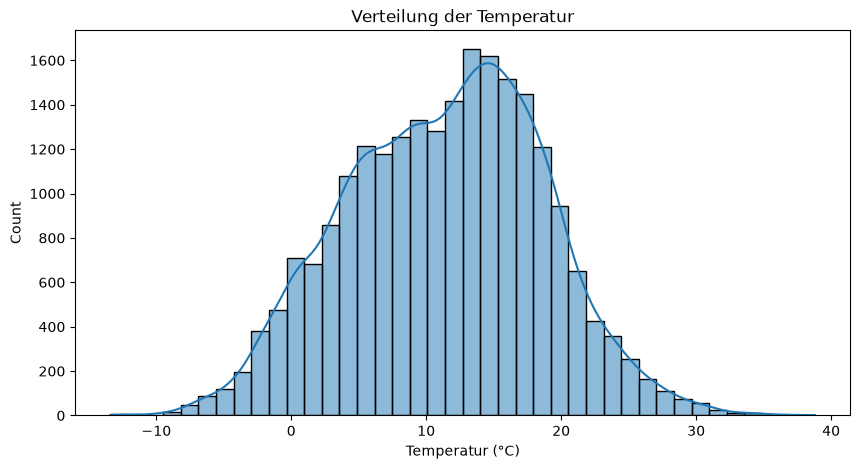

In [25]:
plt.figure(figsize=(10,5))

sns.histplot(
    df["TT_TU"],
    bins=40,
    kde=True
)

plt.title("Verteilung der Temperatur")
plt.xlabel("Temperatur (°C)")
plt.show()

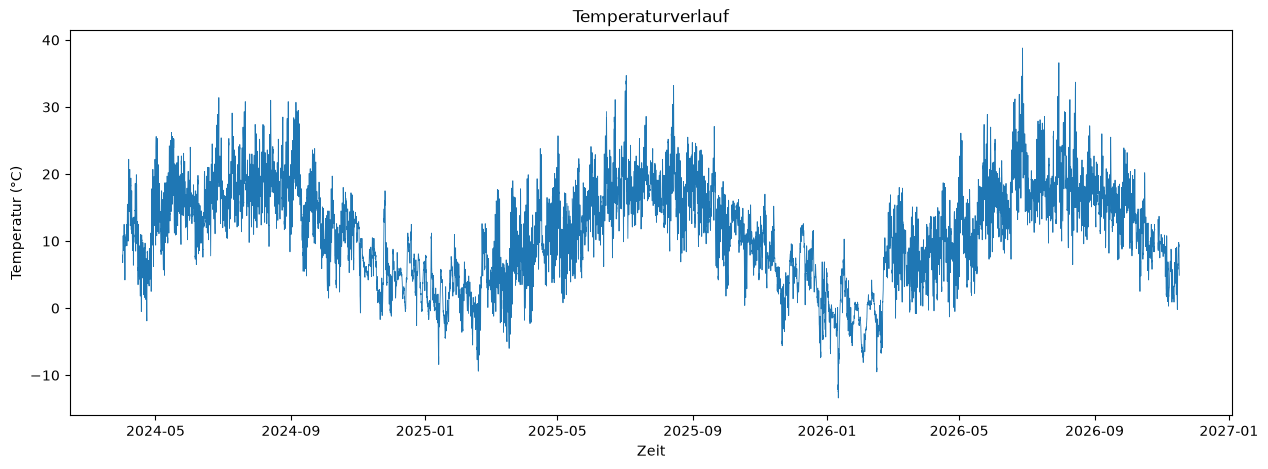

In [26]:
plt.figure(figsize=(15,5))

plt.plot(
    df["time"],
    df["TT_TU"],
    linewidth=0.6
)

plt.title("Temperaturverlauf")
plt.xlabel("Zeit")
plt.ylabel("Temperatur (°C)")
plt.show()

In [31]:
df["hour"] = df["time"].dt.hour

hourly_temp = (
    df.groupby("hour")["TT_TU"]
      .mean()
      .reset_index()
)

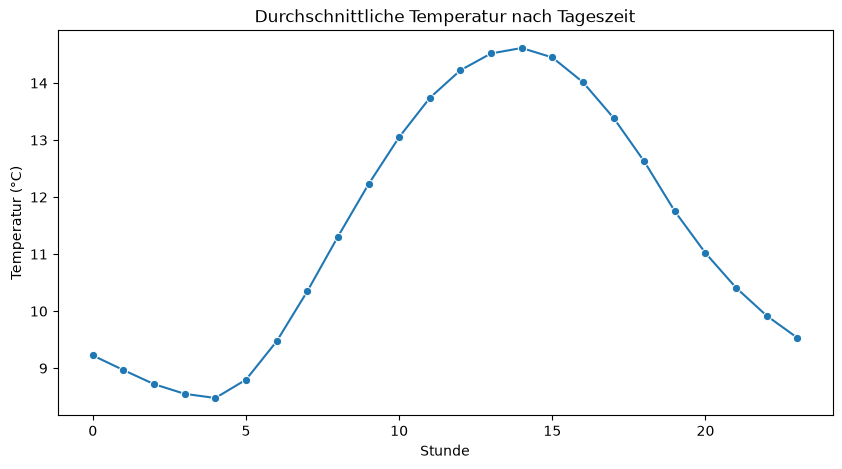

In [32]:
plt.figure(figsize=(10,5))

sns.lineplot(
    data=hourly_temp,
    x="hour",
    y="TT_TU",
    marker="o"
)

plt.title("Durchschnittliche Temperatur nach Tageszeit")
plt.xlabel("Stunde")
plt.ylabel("Temperatur (°C)")
plt.show()

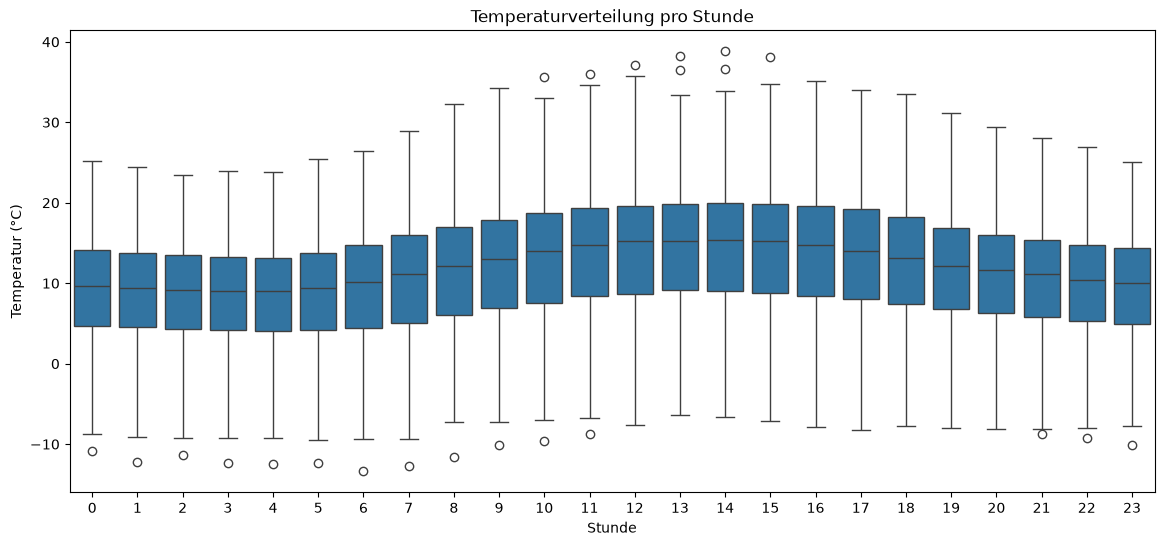

In [29]:
plt.figure(figsize=(14,6))

sns.boxplot(
    data=df,
    x="hour",
    y="TT_TU"
)

plt.title("Temperaturverteilung pro Stunde")
plt.xlabel("Stunde")
plt.ylabel("Temperatur (°C)")
plt.show()

In [33]:
df["month"] = df["time"].dt.to_period("M")

monthly = (
    df.groupby("month")["TT_TU"]
      .mean()
      .reset_index()
)

monthly["month"] = monthly["month"].astype(str)


In [40]:
df["hour"] = df["time"].dt.hour
df["month"] = df["time"].dt.month

heatmap_data = (
    df.groupby(["month", "hour"])["TT_TU"]
      .mean()
      .unstack()
)

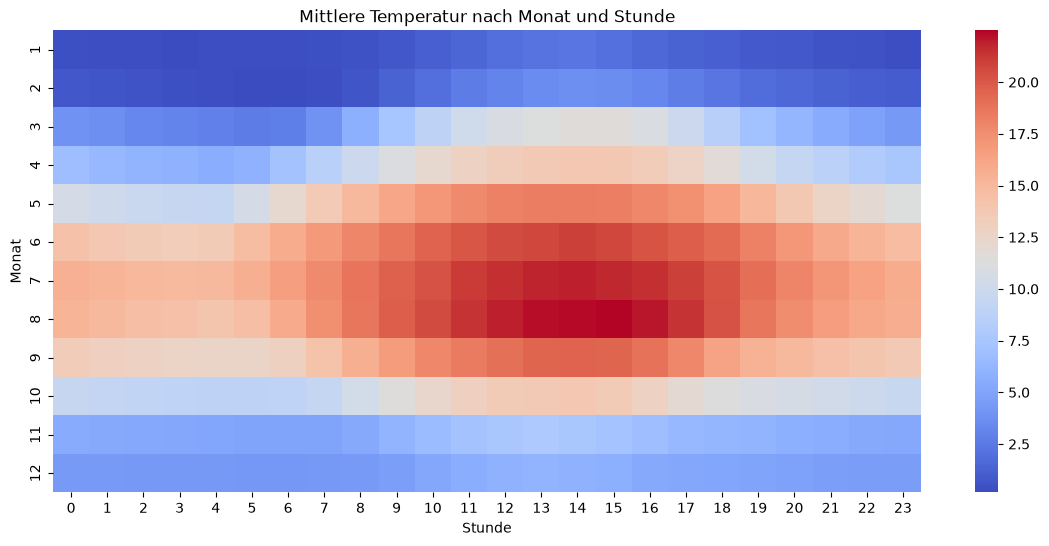

In [39]:
plt.figure(figsize=(14,6))

sns.heatmap(
    heatmap_data,
    cmap="coolwarm"
)

plt.title("Mittlere Temperatur nach Monat und Stunde")
plt.xlabel("Stunde")
plt.ylabel("Monat")

plt.show()

In [ ]:
#Temperatur und Luftfeuchtigkeit

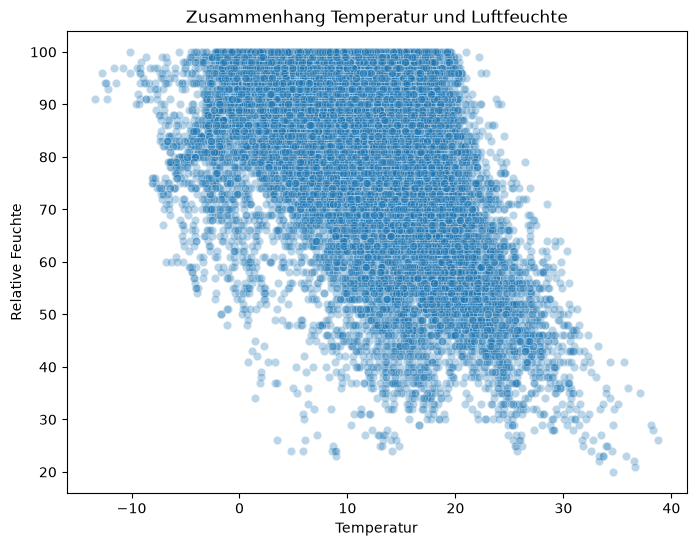

In [35]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df,
    x="TT_TU",
    y="RF_TU",
    alpha=0.3
)

plt.xlabel("Temperatur")
plt.ylabel("Relative Feuchte")
plt.title("Zusammenhang Temperatur und Luftfeuchte")

plt.show()

In [36]:
print(
    df[["TT_TU", "RF_TU"]]
    .corr()
)

          TT_TU     RF_TU
TT_TU  1.000000 -0.518429
RF_TU -0.518429  1.000000
